In [3]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import nest
from pathlib import Path
from pynestml.frontend.pynestml_frontend import generate_nest_target

# ---------- paths and model names ----------
SOURCE = Path("hh_neuron_sca13_final.nestml").resolve()
assert SOURCE.is_file(), SOURCE
MODULE_NAME = "sca13_final_module"
MODEL = "hh_neuron_sca13_final_nestml"
TARGET = Path("target_final").resolve()
RESULTS = Path("taskB_results")
RESULTS.mkdir(exist_ok=True)

# ---------- build ----------
# The C++ build succeeds. The final "make install" step fails because the
# NEST system folder is read-only on EBRAINS. We ignore that step and load
# the freshly built .so from the target folder directly.
try:
    generate_nest_target(input_path=str(SOURCE), target_path=str(TARGET),
                         module_name=MODULE_NAME, suffix="_nestml")
except Exception as e:
    print("pyNESTML reported an install error (expected on EBRAINS):", type(e).__name__)
    print("Build step completed; continuing with the local .so.")

MODULE = TARGET / (MODULE_NAME + ".so")
assert MODULE.is_file(), (f"Built module not found: {MODULE}. "
                          f"Contents of target: {[p.name for p in TARGET.iterdir()]}")
print("Module:", MODULE)

# ---------- constants ----------
DT = 0.005            # ms, validated timestep
T0 = 50.0             # ms, equilibration before first pulse
TRAIN_MS = 100.0      # nominal train length
AP_THRESHOLD = -10.0  # mV, Macica failure criterion
WT_KV = 150.0         # nS
WT_LT = 27.0          # nS, calibrated Model A
WT_NA = 510.0         # nS

# Protocol 1: calibration protocol (1400 pA, 0.25 ms)
# Protocol 2: Macica Fig. 1 protocol (2 nA, 0.3 ms)
PROTOCOLS = {"P1 1400pA/0.25ms": (1400.0, 0.25),
             "P2 2000pA/0.30ms": (2000.0, 0.30)}

# ---------- load and verify defaults ----------
nest.ResetKernel()
nest.Install(str(MODULE))
for k, v in {"g_LT": WT_LT, "g_Na": WT_NA, "g_L": 2.0, "C_m": 10.0, "E_L": -63.0}.items():
    assert np.isclose(nest.GetDefaults(MODEL)[k], v), k
print("Model loaded and defaults verified.")


              -- N E S T --
  Copyright (C) 2004 The NEST Initiative

 Version: 3.9.0
 Built: Nov  4 2025 17:52:39

 This program is provided AS IS and comes with
 NO WARRANTY. See the file LICENSE for details.

 Problems or suggestions?
   Visit https://www.nest-simulator.org

 Type 'nest.help()' to find out more about NEST.

Float.__new__() missing 1 required positional argument: 'num'
CMake Warning:
  Ignoring empty string ("") provided on the command line.


-- The CXX compiler identification is GNU 13.3.0
-- Detecting CXX compiler ABI info
-- Detecting CXX compiler ABI info - done
-- Check for working CXX compiler: /usr/bin/g++ - skipped
-- Detecting CXX compile features
-- Detecting CXX compile features - done

-------------------------------------------------------
sca13_final_module Configuration Summary
-------------------------------------------------------

C++ compiler         : /usr/bin/g++
Build static libs    : OFF
C++ compiler flags   : 
NEST compiler flags  :  -std=c+

In [5]:
def round_time(t):
    # Same convention as the calibrated notebook (GRID_ROUNDING = False)
    return round(t, 2)

def run_train(g_kv31, freq, amp, dur, g_lt=WT_LT):
    n_pulses = int(freq * TRAIN_MS / 1000.0)
    nest.ResetKernel()
    nest.set_verbosity("M_ERROR")
    nest.SetKernelStatus({"resolution": DT})
    if MODEL not in nest.node_models:
        nest.Install(str(MODULE))

    neuron = nest.Create(MODEL, params={"g_Kv31": g_kv31, "g_LT": g_lt})
    mm = nest.Create("multimeter", params={"record_from": ["V_m"], "interval": DT})
    nest.Connect(mm, neuron)

    period = 1000.0 / freq
    starts = [round_time(T0 + k * period) for k in range(n_pulses)]
    times, values = [], []
    for s in starts:
        times += [s, round_time(s + dur)]
        values += [amp, 0.0]
    gen = nest.Create("step_current_generator",
                      params={"amplitude_times": times, "amplitude_values": values})
    nest.Connect(gen, neuron, syn_spec={"delay": DT})
    nest.Simulate(round_time(starts[-1] + 40.0))

    ev = mm.get("events")
    t = np.array(ev["times"])
    V = np.array(ev["V_m"])
    peaks, delays = [], []
    for i, s in enumerate(starts):
        end = starts[i + 1] if i + 1 < len(starts) else s + period
        window = (t >= s + DT) & (t < end + DT)
        k = np.argmax(V[window])
        peaks.append(V[window][k])
        delays.append(t[window][k] - s)
    peaks = np.array(peaks)
    return {"t": t, "V": V, "starts": np.array(starts), "peaks": peaks,
            "delay": np.array(delays), "ok": peaks >= AP_THRESHOLD}

def summarise(r):
    ok = r["ok"]
    p = r["peaks"][ok]
    d = r["delay"][ok]
    # AP attenuation: mean of first k successful peaks minus mean of last k
    if p.size >= 2:
        k = max(1, min(3, p.size // 2))
        drop = float(p[:k].mean() - p[-k:].mean())
    else:
        drop = np.nan
    return dict(Failures=int((~ok).sum()),
                Reliability=100.0 * ok.mean(),
                Mean_delay=d.mean() if d.size else np.nan,
                Jitter=d.std() if d.size else np.nan,
                Mean_peak=p.mean() if p.size else np.nan,
                Peak_drop=drop)

def run_grid(gkv_list, lt_list, freqs, protocols):
    rows, raw = [], {}
    for pname, (amp, dur) in protocols.items():
        for g in gkv_list:
            for lt in lt_list:
                for f in freqs:
                    r = run_train(g, f, amp, dur, g_lt=lt)
                    rows.append(dict(Protocol=pname, gKv31=g, gLT=lt,
                                     Frequency=f, **summarise(r)))
                    raw[(pname, g, lt, f)] = r
    return pd.DataFrame(rows), raw

pd.set_option("display.width", 160)

,Protocol,gKv31,gLT,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak,Peak_drop
0,P1 1400pA/0.25ms,150.0,27.0,100,0,100.0,0.404,0.003,43.247,-0.383
1,P1 1400pA/0.25ms,150.0,27.0,200,0,100.0,0.451,0.013,42.647,-0.189
2,P1 1400pA/0.25ms,150.0,27.0,300,0,100.0,0.547,0.030,39.564,0.639
3,P1 1400pA/0.25ms,27.0,27.0,100,0,100.0,0.400,0.000,42.816,-0.199
4,P1 1400pA/0.25ms,27.0,27.0,200,0,100.0,0.438,0.009,40.812,0.194
5,P1 1400pA/0.25ms,27.0,27.0,300,0,100.0,0.562,0.030,29.943,4.297
6,P1 1400pA/0.25ms,15.0,27.0,100,0,100.0,0.400,0.000,42.570,-0.097
7,P1 1400pA/0.25ms,15.0,27.0,200,0,100.0,0.448,0.011,39.537,0.759
8,P1 1400pA/0.25ms,15.0,27.0,300,0,100.0,0.611,0.040,24.240,8.012
9,P1 1400pA/0.25ms,0.0,27.0,100,0,100.0,0.405,0.002,42.054,0.124


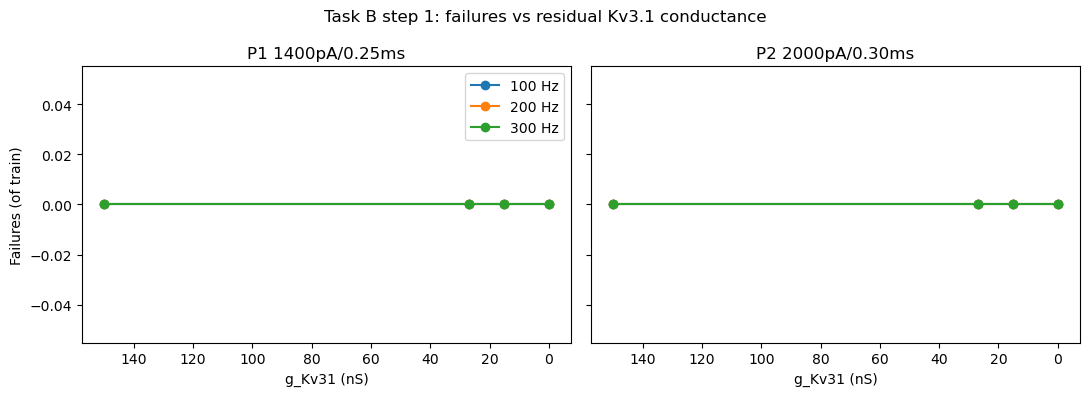

In [6]:
STEP1_GKV = [150.0, 27.0, 15.0, 0.0]
FREQS = [100, 200, 300]

df1, raw1 = run_grid(STEP1_GKV, [WT_LT], FREQS, PROTOCOLS)
df1.to_csv(RESULTS / "step1_gKv_protocols.csv", index=False)
display(df1.round(3))

fig, axes = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for ax, pname in zip(axes, PROTOCOLS):
    for f in FREQS:
        s = df1[(df1.Protocol == pname) & (df1.Frequency == f)].sort_values("gKv31")
        ax.plot(s.gKv31, s.Failures, "o-", label=f"{f} Hz")
    ax.set_title(pname)
    ax.set_xlabel("g_Kv31 (nS)")
    ax.invert_xaxis()
axes[0].set_ylabel("Failures (of train)")
axes[0].legend()
fig.suptitle("Task B step 1: failures vs residual Kv3.1 conductance")
fig.tight_layout()
fig.savefig(RESULTS / "step1_failures.png", dpi=200, bbox_inches="tight")
plt.show()

In [7]:
TEA_GKV = [15.0, 20.0, 27.0, 35.0, 45.0]

df2, raw2 = run_grid(TEA_GKV, [WT_LT], FREQS, PROTOCOLS)
df2.to_csv(RESULTS / "step2_TEA_sweep.csv", index=False)

# Macica Fig. 1: TEA loses full APs at 300 Hz; model should show failures at 300 Hz
piv = df2[df2.Frequency == 300].pivot_table(index="gKv31", columns="Protocol",
                                            values="Failures")
print("Failures at 300 Hz vs residual g_HT (Macica TEA: failures expected):")
display(piv)
display(df2.round(3))

Failures at 300 Hz vs residual g_HT (Macica TEA: failures expected):


Protocol,P1 1400pA/0.25ms,P2 2000pA/0.30ms
gKv31,,
15.0,0.0,0.0
20.0,0.0,0.0
27.0,0.0,0.0
35.0,0.0,0.0
45.0,0.0,0.0


,Protocol,gKv31,gLT,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak,Peak_drop
0,P1 1400pA/0.25ms,15.0,27.0,100,0,100.0,0.400,0.000,42.570,-0.097
1,P1 1400pA/0.25ms,15.0,27.0,200,0,100.0,0.448,0.011,39.537,0.759
2,P1 1400pA/0.25ms,15.0,27.0,300,0,100.0,0.611,0.040,24.240,8.012
3,P1 1400pA/0.25ms,20.0,27.0,100,0,100.0,0.400,0.000,42.686,-0.146
4,P1 1400pA/0.25ms,20.0,27.0,200,0,100.0,0.443,0.010,40.148,0.479
5,P1 1400pA/0.25ms,20.0,27.0,300,0,100.0,0.588,0.035,26.934,6.215
6,P1 1400pA/0.25ms,27.0,27.0,100,0,100.0,0.400,0.000,42.816,-0.199
7,P1 1400pA/0.25ms,27.0,27.0,200,0,100.0,0.438,0.009,40.812,0.194
8,P1 1400pA/0.25ms,27.0,27.0,300,0,100.0,0.562,0.030,29.943,4.297
9,P1 1400pA/0.25ms,35.0,27.0,100,0,100.0,0.400,0.000,42.929,-0.245


In [8]:
KO_GKV = [0.0, 5.0, 10.0, 15.0]

df3, raw3 = run_grid(KO_GKV, [WT_LT], FREQS, PROTOCOLS)
df3.to_csv(RESULTS / "step3_KO_sweep.csv", index=False)
display(df3.round(3))

# A separate residual Kv3.3 current is NOT in the NESTML model.
# It would need a new conductance parameter in the .nestml file, which is not
# created here. Only the g_Kv31 residual is tested.

,Protocol,gKv31,gLT,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak,Peak_drop
0,P1 1400pA/0.25ms,0.0,27.0,100,0,100.0,0.405,0.002,42.054,0.124
1,P1 1400pA/0.25ms,0.0,27.0,200,0,100.0,0.466,0.015,36.723,2.142
2,P1 1400pA/0.25ms,0.0,27.0,300,0,100.0,0.705,0.060,13.743,14.812
3,P1 1400pA/0.25ms,5.0,27.0,100,0,100.0,0.405,0.002,42.261,0.034
4,P1 1400pA/0.25ms,5.0,27.0,200,0,100.0,0.457,0.013,37.860,1.571
5,P1 1400pA/0.25ms,5.0,27.0,300,0,100.0,0.671,0.053,17.503,12.516
6,P1 1400pA/0.25ms,10.0,27.0,100,0,100.0,0.405,0.002,42.429,-0.038
7,P1 1400pA/0.25ms,10.0,27.0,200,0,100.0,0.452,0.012,38.785,1.117
8,P1 1400pA/0.25ms,10.0,27.0,300,0,100.0,0.638,0.046,21.071,10.155
9,P1 1400pA/0.25ms,15.0,27.0,100,0,100.0,0.400,0.000,42.570,-0.097


In [9]:
# Steady-state I_HT at +10 mV using the model's own n and p equations.
# This is an analytic voltage-clamp proxy, not a simulated voltage clamp.
def ht_steady_state_current(g, V=10.0, E_K=-80.0):
    a_n = 0.2719 * np.exp(0.04 * V); b_n = 0.1974
    n_inf = a_n / (a_n + b_n)
    a_p = 0.00713 * np.exp(-0.1942 * V); b_p = 0.0935 * np.exp(0.0058 * V)
    p_inf = a_p / (a_p + b_p)
    return g * n_inf**3 * (0.8 + 0.2 * p_inf) * (V - E_K)  # pA

I_wt = ht_steady_state_current(WT_KV)
vc_rows = []
for g in sorted(set(STEP1_GKV + TEA_GKV + KO_GKV)):
    I = ht_steady_state_current(g)
    vc_rows.append(dict(gKv31=g, I_HT_pA=I, Retained_pct=100 * I / I_wt,
                        Block_pct=100 - 100 * I / I_wt))
vc = pd.DataFrame(vc_rows)
display(vc.round(2))

# Experimental targets: TEA ~75% block (Wang 1998); KO >90% loss (Macica 2003)
print("Target: TEA block ~75%  ->  model 27 nS block =",
      round(float(vc.loc[vc.gKv31 == 27.0, "Block_pct"].iloc[0]), 1), "%")
print("Target: KO loss >90%    ->  model 15 nS loss =",
      round(float(vc.loc[vc.gKv31 == 15.0, "Block_pct"].iloc[0]), 1), "%")
vc.to_csv(RESULTS / "voltage_clamp_proxy.csv", index=False)

,gKv31,I_HT_pA,Retained_pct,Block_pct
0,0.0,0.00,0.00,100.00
1,5.0,109.85,3.33,96.67
2,10.0,219.69,6.67,93.33
3,15.0,329.54,10.00,90.00
4,20.0,439.38,13.33,86.67
5,27.0,593.16,18.00,82.00
6,35.0,768.92,23.33,76.67
7,45.0,988.61,30.00,70.00
8,150.0,3295.35,100.00,0.00


Target: TEA block ~75%  ->  model 27 nS block = 82.0 %
Target: KO loss >90%    ->  model 15 nS loss = 90.0 %


In [10]:
KO_REP = 15.0          # representative KO residual conductance
WT_REP = WT_KV         # WT control, must stay at calibrated behaviour
LT_SWEEP = [20.0, 22.0, 25.0, 27.0, 30.0, 35.0]
FREQS_LT = [200, 300]

df_ko, _ = run_grid([KO_REP], LT_SWEEP, FREQS_LT, PROTOCOLS)
df_wt, _ = run_grid([WT_REP], LT_SWEEP, FREQS_LT, PROTOCOLS)
df_lt = pd.concat([df_ko.assign(Genotype="KO"), df_wt.assign(Genotype="WT")],
                  ignore_index=True)

# Criteria (from Macica Fig. 1 text; thresholds are analysis choices):
#   KO: AP attenuation at 200 Hz (Peak_drop >= 5 mV) and failures at 300 Hz (> 0)
#   WT: no failures at 300 Hz and no attenuation at 200 Hz (Peak_drop < 5 mV)
def check_row(row):
    if row.Genotype == "KO":
        if row.Frequency == 200:
            return bool(row.Peak_drop >= 5.0)
        if row.Frequency == 300:
            return bool(row.Failures > 0)
    else:
        if row.Frequency == 300:
            return bool(row.Failures == 0)
        if row.Frequency == 200:
            return bool(np.isnan(row.Peak_drop) or row.Peak_drop < 5.0)
    return False

df_lt["Pass"] = df_lt.apply(check_row, axis=1)
df_lt.to_csv(RESULTS / "step4_KO_gLT_sweep.csv", index=False)
display(df_lt.round(3))

# Summarise: which g_LT values satisfy both KO criteria AND keep WT intact
summary = []
for lt in LT_SWEEP:
    for pname in PROTOCOLS:
        sub = df_lt[(df_lt.gLT == lt) & (df_lt.Protocol == pname)]
        ko_ok = bool(sub[(sub.Genotype == "KO")].Pass.all())
        wt_ok = bool(sub[(sub.Genotype == "WT")].Pass.all())
        summary.append(dict(gLT=lt, Protocol=pname, KO_pass=ko_ok, WT_preserved=wt_ok,
                            Candidate=ko_ok and wt_ok))
summary = pd.DataFrame(summary)
summary.to_csv(RESULTS / "step4_candidate_summary.csv", index=False)
print("KO-specific g_LT candidates (KO criteria met and WT preserved):")
display(summary)

,Protocol,gKv31,gLT,Frequency,Failures,Reliability,Mean_delay,Jitter,Mean_peak,Peak_drop,Genotype,Pass
0,P1 1400pA/0.25ms,15.0,20.0,200,0,100.0,0.467,0.014,37.847,1.256,KO,False
1,P1 1400pA/0.25ms,15.0,20.0,300,0,100.0,0.799,0.081,4.935,23.102,KO,False
2,P1 1400pA/0.25ms,15.0,22.0,200,0,100.0,0.462,0.014,38.472,1.072,KO,False
3,P1 1400pA/0.25ms,15.0,22.0,300,0,100.0,0.735,0.067,12.558,17.006,KO,False
4,P1 1400pA/0.25ms,15.0,25.0,200,0,100.0,0.452,0.012,39.179,0.866,KO,False
5,P1 1400pA/0.25ms,15.0,25.0,300,0,100.0,0.648,0.047,20.842,10.349,KO,False
6,P1 1400pA/0.25ms,15.0,27.0,200,0,100.0,0.448,0.011,39.537,0.759,KO,False
7,P1 1400pA/0.25ms,15.0,27.0,300,0,100.0,0.611,0.040,24.240,8.012,KO,False
8,P1 1400pA/0.25ms,15.0,30.0,200,0,100.0,0.438,0.009,39.956,0.624,KO,False
9,P1 1400pA/0.25ms,15.0,30.0,300,0,100.0,0.573,0.032,27.732,5.894,KO,False


KO-specific g_LT candidates (KO criteria met and WT preserved):


,gLT,Protocol,KO_pass,WT_preserved,Candidate
0,20.0,P1 1400pA/0.25ms,False,True,False
1,20.0,P2 2000pA/0.30ms,False,True,False
2,22.0,P1 1400pA/0.25ms,False,True,False
3,22.0,P2 2000pA/0.30ms,False,True,False
4,25.0,P1 1400pA/0.25ms,False,True,False
5,25.0,P2 2000pA/0.30ms,False,True,False
6,27.0,P1 1400pA/0.25ms,False,True,False
7,27.0,P2 2000pA/0.30ms,False,True,False
8,30.0,P1 1400pA/0.25ms,False,True,False
9,30.0,P2 2000pA/0.30ms,False,True,False


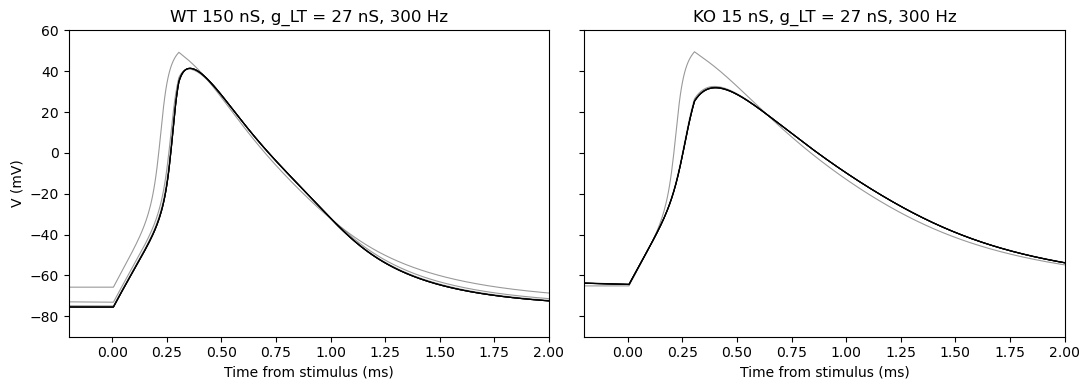

In [11]:
# Plot first and last successful APs at 300 Hz (P2) for WT and KO at g_LT = 27 nS
fig, ax = plt.subplots(1, 2, figsize=(11, 4), sharey=True)
for a, (lab, g) in zip(ax, [("WT 150 nS", WT_REP), ("KO 15 nS", KO_REP)]):
    r = run_train(g, 300, 2000.0, 0.30, g_lt=WT_LT)
    for i, s in enumerate(r["starts"][:12]):
        if not r["ok"][i]:
            continue
        w = (r["t"] >= s - 0.2) & (r["t"] <= s + 2.0)
        a.plot(r["t"][w] - s, r["V"][w], color="black", alpha=0.4, lw=0.8)
    a.set_title(f"{lab}, g_LT = {WT_LT:.0f} nS, 300 Hz")
    a.set_xlabel("Time from stimulus (ms)")
    a.set_xlim(-0.2, 2.0)
    a.set_ylim(-90, 60)
ax[0].set_ylabel("V (mV)")
fig.tight_layout()
fig.savefig(RESULTS / "step4_AP_shape_300Hz.png", dpi=200, bbox_inches="tight")
plt.show()